TC1 Accuracy: 1.0
TC2 Accuracy: 1.0
TC3 Predicted Class: 0
TC3 Decision Value: -0.9995884527518395


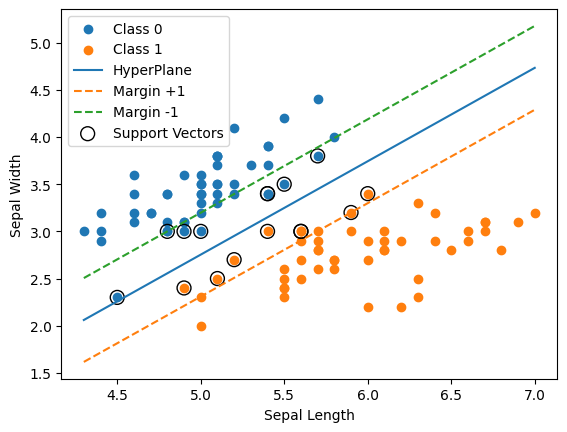

In [4]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

# Load Iris Dataset
iris = load_iris()
X, y = iris.data, iris.target

# TC1: Linearly Separable Data
X1, y1 = X[y != 2], y[y != 2]

m = SVC(kernel='linear')
m.fit(X1, y1)

print("TC1 Accuracy:", accuracy_score(y1, m.predict(X1)))

# TC2: Two Class Dataset
a, b, c, d = train_test_split(
    X1, y1, test_size=0.2, random_state=42)

m2 = SVC(kernel='linear')
m2.fit(a, c)

print("TC2 Accuracy:", accuracy_score(d, m2.predict(b)))

# TC3: Support Vector
m3 = SVC(kernel='linear')
m3.fit(X1, y1)

p = m3.support_vectors_[0].reshape(1, -1)

print("TC3 Predicted Class:", m3.predict(p)[0])
print("TC3 Decision Value:", m3.decision_function(p)[0])

# Graph
Xg = X1[:, [0, 1]]
m = SVC(kernel='linear')
m.fit(Xg, y1)

plt.scatter(Xg[y1==0, 0], Xg[y1==0, 1], label="Class 0")
plt.scatter(Xg[y1==1, 0], Xg[y1==1, 1], label="Class 1")

x = np.linspace(Xg[:,0].min(), Xg[:,0].max(), 100)
w = m.coef_[0]
b = m.intercept_[0]

# Hyperplane
yline = -(w[0]*x+b)/w[1]
plt.plot(x, yline, label="HyperPlane")

# Margins
plt.plot(x, -(w[0]*x+b-1)/w[1], '--', label="Margin +1")
plt.plot(x, -(w[0]*x+b+1)/w[1], '--', label="Margin -1")

# Support Vectors
plt.scatter(m.support_vectors_[:,0],
            m.support_vectors_[:,1],
            facecolors='none', edgecolors='black',
            s=100, label="Support Vectors")

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.legend()
plt.show()
